# Infinite-width Gaussian-RBF kernel solution of the biharmonic flower problem

This notebook solves the **same manufactured biharmonic problem and 5-petal
geometry** as the supplied MATLAB code, but with the analytic infinite-width
Gaussian-RBF kernel.

Manufactured field:
\[
u_{\rm ex}(x,y)=\sin(5\pi x)\cos(5\pi y).
\]

Since
\[
\Delta u_{\rm ex}=-(k_x^2+k_y^2)u_{\rm ex},
\]
the biharmonic forcing is
\[
\Delta^2 u_{\rm ex}=(k_x^2+k_y^2)^2u_{\rm ex}.
\]

Flower geometry:
\[
r_b(\theta)=0.33+0.10\cos(5\theta),
\]
centered at \((0.5,0.5)\).

Both exact boundary conditions from the source problem are imposed:
\[
u=u_{\rm ex},\qquad \partial_nu=\partial_nu_{\rm ex}.
\]

The kernel implementation evaluates all derivatives needed by \(\Delta^2\)
analytically from the continuum Gaussian feature distribution, including
fourth derivatives in each kernel argument.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
from time import perf_counter


In [2]:
import numpy as np
from scipy.special import erf
from math import comb

# ---------- geometry ----------
def flower_radius(theta, R0=0.33, A=0.10, n_petals=5):
    theta = np.asarray(theta, dtype=float)
    return R0 + A*np.cos(n_petals*theta)

def flower_radius_prime(theta, A=0.10, n_petals=5):
    theta = np.asarray(theta, dtype=float)
    return -A*n_petals*np.sin(n_petals*theta)

def flower_boundary(theta, cx=0.5, cy=0.5, R0=0.33, A=0.10, n_petals=5):
    theta = np.asarray(theta, dtype=float)
    r = flower_radius(theta, R0, A, n_petals)
    rp = flower_radius_prime(theta, A, n_petals)
    ct, st = np.cos(theta), np.sin(theta)
    x = cx + r*ct
    y = cy + r*st
    dx = rp*ct - r*st
    dy = rp*st + r*ct
    # For CCW parameterization, outward normal is (dy,-dx)
    nrm = np.hypot(dx,dy)
    nx = dy/nrm
    ny = -dx/nrm
    return x,y,nx,ny

def flower_inside(x, y, cx=0.5, cy=0.5, R0=0.33, A=0.10, n_petals=5):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    dx = x-cx
    dy = y-cy
    rr = np.hypot(dx,dy)
    th = np.arctan2(dy,dx)
    return rr <= flower_radius(th,R0,A,n_petals)

def radical_inverse_scalar(n,b):
    r=0.0
    f=1.0/b
    while n>0:
        r += f*(n % b)
        n //= b
        f /= b
    return r

def halton_flower(N, skip=0, cx=0.5, cy=0.5, R0=0.33, A=0.10, n_petals=5):
    x=np.zeros(N)
    y=np.zeros(N)
    count=0
    idx=skip+1
    while count<N:
        xx=radical_inverse_scalar(idx,2)
        yy=radical_inverse_scalar(idx,3)
        if flower_inside(xx,yy,cx,cy,R0,A,n_petals):
            x[count]=xx
            y[count]=yy
            count += 1
        idx += 1
    return x,y

# ---------- exact continuum Gaussian kernel derivatives ----------
# Probabilists' Hermite polynomial coefficients, ascending powers.
_HERMITE = {
    0: np.array([1.0]),
    1: np.array([0.0,1.0]),
    2: np.array([-1.0,0.0,1.0]),
    3: np.array([0.0,-3.0,0.0,1.0]),
    4: np.array([3.0,0.0,-6.0,0.0,1.0]),
}

def _poly_shift_power(k, A, signA, sigma):
    """
    Coefficients in z for ((signA*A - z)/sigma)^k.
    Returns list coeff[j] multiplying z^j, each coeff has A's matrix shape.
    """
    out=[]
    base = signA*A
    for j in range(k+1):
        out.append(comb(k,j) * (base**(k-j)) * ((-1.0)**j) / (sigma**k))
    return out

def rbf1d_uniform_derivative(x, y, sigma, ca, cb, p, q):
    """
    Exact d^(p+q)/(dx^p dy^q) E_c[phi_c(x) phi_c(y)]
    for c ~ Uniform[ca,cb], p,q in {0,...,4}.
    """
    if p not in _HERMITE or q not in _HERMITE:
        raise ValueError("Derivative order must be between 0 and 4.")

    x=np.asarray(x,dtype=float).reshape(-1,1)
    y=np.asarray(y,dtype=float).reshape(1,-1)

    mid=0.5*(x+y)
    d=x-y
    A=0.5*d
    za=ca-mid
    zb=cb-mid

    Ed=np.exp(-(d*d)/(4*sigma*sigma))
    ea=np.exp(-(za/sigma)**2)
    eb=np.exp(-(zb/sigma)**2)
    E=erf(zb/sigma)-erf(za/sigma)

    # Moments J_n = integral z^n exp(-z^2/sigma^2) dz.
    maxn=p+q
    J=[None]*(maxn+1)
    J[0]=0.5*sigma*np.sqrt(np.pi)*E
    if maxn>=1:
        J[1]=0.5*sigma*sigma*(ea-eb)
    for n in range(2,maxn+1):
        boundary = zb**(n-1)*eb - za**(n-1)*ea
        J[n] = -0.5*sigma*sigma*boundary + 0.5*sigma*sigma*(n-1)*J[n-2]

    hp=_HERMITE[p]
    hq=_HERMITE[q]

    # Polynomial coefficients of He_p((A-z)/sigma)*He_q((-A-z)/sigma).
    coeff=[np.zeros_like(A) for _ in range(maxn+1)]
    for kp,ap in enumerate(hp):
        if ap==0: 
            continue
        pp=_poly_shift_power(kp,A,+1.0,sigma)
        for kq,aq in enumerate(hq):
            if aq==0:
                continue
            qq=_poly_shift_power(kq,A,-1.0,sigma)
            for i,ci in enumerate(pp):
                for j,cj in enumerate(qq):
                    coeff[i+j] += ap*aq*ci*cj

    integ=np.zeros_like(A)
    for n in range(maxn+1):
        integ += coeff[n]*J[n]

    pref = ((-1.0)**(p+q)) / (sigma**(p+q))
    return (Ed * pref * integ) / (cb-ca)

def compute_kernel_norm(cfg):
    xr=0.5*(cfg["c_a"]+cfg["c_b"])
    K0=rbf1d_uniform_derivative([xr],[xr],cfg["sigma"],cfg["c_a"],cfg["c_b"],0,0)
    return float((K0*K0)[0,0])

def k2d_deriv(cfg,x1,y1,x2,y2,px,py,qx,qy):
    Kx=rbf1d_uniform_derivative(x1,x2,cfg["sigma"],cfg["c_a"],cfg["c_b"],px,qx)
    Ky=rbf1d_uniform_derivative(y1,y2,cfg["sigma"],cfg["c_a"],cfg["c_b"],py,qy)
    return (Kx*Ky)/cfg["norm_const"]

_BIH=[(4,0,1.0),(2,2,2.0),(0,4,1.0)]

def k_bih_bih(cfg,x1,y1,x2,y2):
    out=0.0
    for px,py,wp in _BIH:
        for qx,qy,wq in _BIH:
            out = out + wp*wq*k2d_deriv(cfg,x1,y1,x2,y2,px,py,qx,qy)
    return out

def k_bih_val(cfg,x1,y1,x2,y2):
    out=0.0
    for px,py,w in _BIH:
        out = out + w*k2d_deriv(cfg,x1,y1,x2,y2,px,py,0,0)
    return out

def k_val_bih(cfg,x1,y1,x2,y2):
    out=0.0
    for qx,qy,w in _BIH:
        out = out + w*k2d_deriv(cfg,x1,y1,x2,y2,0,0,qx,qy)
    return out

def k_val_val(cfg,x1,y1,x2,y2):
    return k2d_deriv(cfg,x1,y1,x2,y2,0,0,0,0)

def k_normal_first(cfg,x1,y1,nx1,ny1,x2,y2,qx=0,qy=0):
    return (
        np.asarray(nx1).reshape(-1,1)*k2d_deriv(cfg,x1,y1,x2,y2,1,0,qx,qy)
        + np.asarray(ny1).reshape(-1,1)*k2d_deriv(cfg,x1,y1,x2,y2,0,1,qx,qy)
    )

def k_normal_second(cfg,x1,y1,x2,y2,nx2,ny2,px=0,py=0):
    return (
        k2d_deriv(cfg,x1,y1,x2,y2,px,py,1,0)*np.asarray(nx2).reshape(1,-1)
        + k2d_deriv(cfg,x1,y1,x2,y2,px,py,0,1)*np.asarray(ny2).reshape(1,-1)
    )

def k_bih_normal_second(cfg,x1,y1,x2,y2,nx2,ny2):
    out=0.0
    for px,py,w in _BIH:
        out = out + w*k_normal_second(cfg,x1,y1,x2,y2,nx2,ny2,px,py)
    return out

def k_normal_first_bih(cfg,x1,y1,nx1,ny1,x2,y2):
    out=0.0
    for qx,qy,w in _BIH:
        out = out + w*k_normal_first(cfg,x1,y1,nx1,ny1,x2,y2,qx,qy)
    return out

def k_normal_normal(cfg,x1,y1,nx1,ny1,x2,y2,nx2,ny2):
    nx1=np.asarray(nx1).reshape(-1,1)
    ny1=np.asarray(ny1).reshape(-1,1)
    nx2=np.asarray(nx2).reshape(1,-1)
    ny2=np.asarray(ny2).reshape(1,-1)
    return (
        nx1*nx2*k2d_deriv(cfg,x1,y1,x2,y2,1,0,1,0)
        + nx1*ny2*k2d_deriv(cfg,x1,y1,x2,y2,1,0,0,1)
        + ny1*nx2*k2d_deriv(cfg,x1,y1,x2,y2,0,1,1,0)
        + ny1*ny2*k2d_deriv(cfg,x1,y1,x2,y2,0,1,0,1)
    )

def predict_value(cfg,alpha,xP,yP,xB,yB,nxB,nyB,xq,yq,batch=400):
    xq=np.asarray(xq,float).ravel()
    yq=np.asarray(yq,float).ravel()
    NP=len(xP); NB=len(xB)
    out=np.zeros_like(xq)
    for i1 in range(0,len(xq),batch):
        ids=slice(i1,min(i1+batch,len(xq)))
        qx=xq[ids]; qy=yq[ids]
        KP=k_val_bih(cfg,qx,qy,xP,yP)
        KD=k_val_val(cfg,qx,qy,xB,yB)
        KN=k_normal_second(cfg,qx,qy,xB,yB,nxB,nyB,0,0)
        out[ids]=np.hstack([KP,KD,KN])@alpha
    return out

def predict_bih(cfg,alpha,xP,yP,xB,yB,nxB,nyB,xq,yq,batch=200):
    xq=np.asarray(xq,float).ravel()
    yq=np.asarray(yq,float).ravel()
    out=np.zeros_like(xq)
    for i1 in range(0,len(xq),batch):
        ids=slice(i1,min(i1+batch,len(xq)))
        qx=xq[ids]; qy=yq[ids]
        KP=k_bih_bih(cfg,qx,qy,xP,yP)
        KD=k_bih_val(cfg,qx,qy,xB,yB)
        KN=k_bih_normal_second(cfg,qx,qy,xB,yB,nxB,nyB)
        out[ids]=np.hstack([KP,KD,KN])@alpha
    return out

In [3]:
# ------------------------------ problem ---------------------------------
cx,cy=0.5,0.5
R0=0.33
A=0.10
n_petals=5

kx=5*np.pi
ky=5*np.pi
K2=kx**2+ky**2

def uexact(x,y):
    return np.sin(kx*np.asarray(x))*np.cos(ky*np.asarray(y))

def ux_exact(x,y):
    return kx*np.cos(kx*np.asarray(x))*np.cos(ky*np.asarray(y))

def uy_exact(x,y):
    return -ky*np.sin(kx*np.asarray(x))*np.sin(ky*np.asarray(y))

def ffun(x,y):
    return (K2**2)*uexact(x,y)

# ------------------------ collocation geometry --------------------------
Np=420
Nb=120
Ntest=5000
Nres=2500
Nb_dense=1000

xP,yP=halton_flower(Np,0,cx,cy,R0,A,n_petals)

thetaB=np.arange(Nb)*(2*np.pi/Nb)
xB,yB,nxB,nyB=flower_boundary(thetaB,cx,cy,R0,A,n_petals)
uB=uexact(xB,yB)
unB=nxB*ux_exact(xB,yB)+nyB*uy_exact(xB,yB)

xT,yT=halton_flower(Ntest,100000,cx,cy,R0,A,n_petals)
xR,yR=halton_flower(Nres,200000,cx,cy,R0,A,n_petals)

thetaBd=np.arange(Nb_dense)*(2*np.pi/Nb_dense)
xBd,yBd,nxBd,nyBd=flower_boundary(thetaBd,cx,cy,R0,A,n_petals)

# --------------------------- kernel setup -------------------------------
sigma=0.070
pad=0.16
c_a=-pad
c_b=1.0+pad
ridge_rel=1e-12

cfg={"sigma":sigma,"c_a":c_a,"c_b":c_b}
cfg["norm_const"]=compute_kernel_norm(cfg)

print("INFINITE-RBF BIHARMONIC FLOWER SOLVER")
print(f"PDE points                  = {Np}")
print(f"Boundary points             = {Nb}")
print(f"Gaussian sigma              = {sigma:.4f}")
print(f"Flower geometry             = r(theta)={R0:.2f}+{A:.2f} cos(5 theta)")

INFINITE-RBF BIHARMONIC FLOWER SOLVER
PDE points                  = 420
Boundary points             = 120
Gaussian sigma              = 0.0700
Flower geometry             = r(theta)=0.33+0.10 cos(5 theta)


In [4]:
# ----------------- quick derivative self-check --------------------------
# Symmetry checks for the continuum kernel derivative implementation.
xt=np.array([0.31,0.47])
yt=np.array([0.39,0.55])
K00=k_val_val(cfg,xt,yt,xt,yt)
assert np.all(np.isfinite(K00))
assert np.max(np.abs(K00-K00.T)) < 1e-10
print("Kernel derivative self-check passed.")

Kernel derivative self-check passed.


In [5]:
# ---------------- symmetric dual collocation matrices ------------------
_t_solve_total0 = perf_counter()
_t0 = perf_counter()
#
# Coefficients:
#   alpha = [alpha_P ; alpha_D ; alpha_N]
#
# Representers:
#   PDE       : Delta^2 on second kernel argument
#   Dirichlet : value on second kernel argument
#   Neumann   : n dot grad on second kernel argument

# PDE rows
K_PP=k_bih_bih(cfg,xP,yP,xP,yP)
K_PD=k_bih_val(cfg,xP,yP,xB,yB)
K_PN=k_bih_normal_second(cfg,xP,yP,xB,yB,nxB,nyB)
Amat=np.hstack([K_PP,K_PD,K_PN])
rhsP=ffun(xP,yP)

# Dirichlet boundary rows
B_D_P=k_val_bih(cfg,xB,yB,xP,yP)
B_D_D=k_val_val(cfg,xB,yB,xB,yB)
B_D_N=k_normal_second(cfg,xB,yB,xB,yB,nxB,nyB,0,0)
B_D=np.hstack([B_D_P,B_D_D,B_D_N])

# Neumann boundary rows
B_N_P=k_normal_first_bih(cfg,xB,yB,nxB,nyB,xP,yP)
B_N_D=k_normal_first(cfg,xB,yB,nxB,nyB,xB,yB,0,0)
B_N_N=k_normal_normal(cfg,xB,yB,nxB,nyB,xB,yB,nxB,nyB)
B_N=np.hstack([B_N_P,B_N_D,B_N_N])

Bmat=np.vstack([B_D,B_N])
bBC=np.r_[uB,unB]

print("PDE matrix                  =",Amat.shape)
print("Boundary matrix             =",Bmat.shape)
t_kernel_assembly = perf_counter() - _t0
print(f"kernel/operator assembly time = {t_kernel_assembly:.6f} s")


PDE matrix                  = (420, 660)
Boundary matrix             = (240, 660)
kernel/operator assembly time = 0.663437 s


In [6]:
# --------------------- null-space boundary projection -------------------
_t0 = perf_counter()
alpha_p=np.linalg.pinv(Bmat,rcond=1e-12)@bBC

Ub,sB,Vhb=svd(Bmat,full_matrices=True)
tolB=max(Bmat.shape)*np.finfo(float).eps*np.max(sB)
rankB=int(np.sum(sB>tolB))
Vb=Vhb.T
Q=Vb[:,rankB:]

t_nullspace = perf_counter() - _t0

print(f"Boundary rank                = {rankB}")
print(f"Null-space dimension         = {Q.shape[1]}")
print(f"||B Q||_F                    = {np.linalg.norm(Bmat@Q):.3e}")
print(f"particular BC max error      = {np.max(np.abs(Bmat@alpha_p-bBC)):.3e}")
print(f"constraint/null-space time   = {t_nullspace:.6f} s")


Boundary rank                = 235
Null-space dimension         = 425
||B Q||_F                    = 3.168e-06
particular BC max error      = 1.214e-05
constraint/null-space time   = 0.045683 s


In [7]:
# ------------------------ reduced biharmonic solve ----------------------
_t0 = perf_counter()
Ared=Amat@Q
bred=rhsP-Amat@alpha_p

Ua,sa,Vha=svd(Ared,full_matrices=False)
if sa.size==0 or sa[0]<=0:
    raise RuntimeError("Reduced biharmonic kernel system is singular.")

lam=ridge_rel*sa[0]**2
filt=sa/(sa**2+lam)
eta=Vha.T@(filt*(Ua.T@bred))
alpha=alpha_p+Q@eta

t_reduced_solve = perf_counter() - _t0
t_total_solve = perf_counter() - _t_solve_total0

print(f"Reduced system               = {Ared.shape[0]} x {Ared.shape[1]}")
print(f"ridge lambda                 = {lam:.3e}")
print(f"reduced SVD/solve time       = {t_reduced_solve:.6f} s")
print(f"total assembly+solve time    = {t_total_solve:.6f} s")


Reduced system               = 420 x 425
ridge lambda                 = 6.456e+05
reduced SVD/solve time       = 0.020195 s
total assembly+solve time    = 0.735750 s


In [8]:
# ------------------------------ diagnostics -----------------------------
_t0 = perf_counter()
uT=predict_value(cfg,alpha,xP,yP,xB,yB,nxB,nyB,xT,yT,300)
uT_exact=uexact(xT,yT)
errT=uT-uT_exact

rmse=np.sqrt(np.mean(errT**2))
max_error=np.max(np.abs(errT))

uBd=predict_value(cfg,alpha,xP,yP,xB,yB,nxB,nyB,xBd,yBd,300)
uBd_exact=uexact(xBd,yBd)
bc_dense_u_max=np.max(np.abs(uBd-uBd_exact))

LuR=predict_bih(cfg,alpha,xP,yP,xB,yB,nxB,nyB,xR,yR,120)
resR=LuR-ffun(xR,yR)
res_rms=np.sqrt(np.mean(resR**2))
res_max=np.max(np.abs(resR))

bc_train_max=np.max(np.abs(Bmat@alpha-bBC))
t_prediction = perf_counter() - _t0

print(f"Independent solution RMSE   = {rmse:.6e}")
print(f"Independent max error       = {max_error:.6e}")
print(f"BC train max error          = {bc_train_max:.6e}")
print(f"Dense Dirichlet max error   = {bc_dense_u_max:.6e}")
print(f"Biharmonic residual RMS     = {res_rms:.6e}")
print(f"Biharmonic residual max     = {res_max:.6e}")
print(f"diagnostic prediction time   = {t_prediction:.6f} s")


Independent solution RMSE   = 1.714061e-03
Independent max error       = 6.506831e-03
BC train max error          = 1.213980e-05
Dense Dirichlet max error   = 1.048588e-06
Biharmonic residual RMS     = 2.834416e+03
Biharmonic residual max     = 3.088440e+04
diagnostic prediction time   = 4.752875 s


In [9]:
# ------------------------ regular grid + archive ------------------------
Nplot=220
xg=np.linspace(0,1,Nplot)
yg=np.linspace(0,1,Nplot)
Xg,Yg=np.meshgrid(xg,yg)
mask=flower_inside(Xg,Yg,cx,cy,R0,A,n_petals)

Ug=np.full_like(Xg,np.nan,dtype=float)
Ue=np.full_like(Xg,np.nan,dtype=float)
Rg=np.full_like(Xg,np.nan,dtype=float)

xq=Xg[mask]
yq=Yg[mask]
Ug[mask]=predict_value(cfg,alpha,xP,yP,xB,yB,nxB,nyB,xq,yq,250)
Ue[mask]=uexact(xq,yq)
Rg[mask]=predict_bih(cfg,alpha,xP,yP,xB,yB,nxB,nyB,xq,yq,100)-ffun(xq,yq)

th=np.linspace(0,2*np.pi,1200)
xbnd,ybnd,_,_=flower_boundary(th,cx,cy,R0,A,n_petals)

np.savez_compressed(
    "INF_RBF_BIHARMONIC_FLOWER_RESULTS.npz",
    cx=cx,cy=cy,R0=R0,A=A,n_petals=n_petals,kx=kx,ky=ky,K2=K2,
    Np=Np,Nb=Nb,Ntest=Ntest,Nres=Nres,Nb_dense=Nb_dense,
    sigma=sigma,pad=pad,c_a=c_a,c_b=c_b,ridge_rel=ridge_rel,
    xP=xP,yP=yP,xB=xB,yB=yB,nxB=nxB,nyB=nyB,uB=uB,unB=unB,
    xBd=xBd,yBd=yBd,nxBd=nxBd,nyBd=nyBd,xbnd=xbnd,ybnd=ybnd,
    alpha=alpha,alpha_p=alpha_p,Q=Q,rankB=rankB,tolB=tolB,lam=lam,
    rmse=rmse,max_error=max_error,bc_train_max=bc_train_max,
    bc_dense_u_max=bc_dense_u_max,res_rms=res_rms,res_max=res_max,
    uT=uT,uT_exact=uT_exact,errT=errT,LuR=LuR,resR=resR,
    Nplot=Nplot,xg=xg,yg=yg,Xg=Xg,Yg=Yg,mask=mask,Ug=Ug,Ue=Ue,Rg=Rg,
    t_kernel_assembly=t_kernel_assembly,t_nullspace=t_nullspace,t_reduced_solve=t_reduced_solve,t_total_solve=t_total_solve,t_prediction=t_prediction
)
print("Saved INF_RBF_BIHARMONIC_FLOWER_RESULTS.npz")

Saved INF_RBF_BIHARMONIC_FLOWER_RESULTS.npz


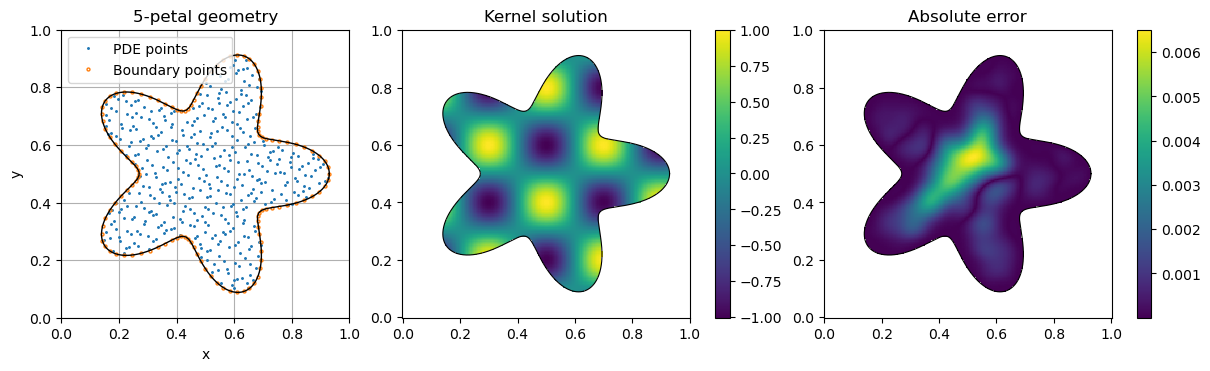

In [10]:
# ------------------------------- plots ----------------------------------
fig,axes=plt.subplots(1,3,figsize=(12,3.6),constrained_layout=True)

ax=axes[0]
ax.plot(xP,yP,".",ms=2.2,label="PDE points")
ax.plot(xB,yB,"o",ms=2.1,mfc="none",label="Boundary points")
ax.plot(xbnd,ybnd,"-k",lw=1.0)
ax.set_aspect("equal")
ax.set(xlim=(0,1),ylim=(0,1),xlabel="x",ylabel="y",title="5-petal geometry")
ax.grid(True)
ax.legend()

im=axes[1].pcolormesh(Xg,Yg,np.ma.masked_invalid(Ug),shading="auto")
axes[1].plot(xbnd,ybnd,"-k",lw=.8)
axes[1].set_aspect("equal")
axes[1].set_title("Kernel solution")
fig.colorbar(im,ax=axes[1])

im=axes[2].pcolormesh(Xg,Yg,np.ma.masked_invalid(np.abs(Ug-Ue)),shading="auto")
axes[2].plot(xbnd,ybnd,"-k",lw=.8)
axes[2].set_aspect("equal")
axes[2].set_title("Absolute error")
fig.colorbar(im,ax=axes[2])

plt.show()